# Phase 7 — Model Evaluation and Validation

## Bank Marketing Subscription Prediction

**Objective:** Evaluate the selected Gradient Boosting model, investigate its generalization performance, analyze classification thresholds, and assess its suitability for identifying potential bank marketing subscribers.

**Selected Model:** Gradient Boosting Classifier

**Evaluation Strategy:**
- Stratified cross-validation
- Validation-set evaluation
- Classification metrics and visualizations
- Overfitting and generalization analysis
- Decision threshold analysis

In [3]:
# Fix Python import path for project modules

import sys
from pathlib import Path

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("src directory exists:", (PROJECT_ROOT / "src").exists())

from src.preprocessing import (
    build_smotenc_model_pipeline,
    split_data
)

print("Project modules imported successfully.")

Project root: /Users/ajeetsherkar/Bank-Marketing-ML-PBL
src directory exists: True
Project modules imported successfully.


In [4]:
# ============================================================
# 1. IMPORTS AND REPRODUCIBILITY
# ============================================================

import json
import warnings
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.ensemble import GradientBoostingClassifier

from imblearn.pipeline import Pipeline as ImbPipeline

from src.preprocessing import (
    build_smotenc_model_pipeline,
    split_data
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_SPLITS = 5

np.random.seed(RANDOM_STATE)

# Detect project root whether notebook starts from
# project root or notebooks directory.
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_data.csv"
COMPARISON_PATH = PROJECT_ROOT / "reports" / "model_comparison.csv"
IMAGE_DIR = PROJECT_ROOT / "images" / "evaluation"
REPORT_DIR = PROJECT_ROOT / "reports"

IMAGE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("PHASE 7 — MODEL EVALUATION")
print("=" * 55)

print("Project root:", PROJECT_ROOT)
print("Python environment ready.")
print("Random state:", RANDOM_STATE)
print("Cross-validation folds:", N_SPLITS)

assert DATA_PATH.exists(), "Cleaned dataset not found."
assert COMPARISON_PATH.exists(), "Phase 6 model comparison CSV not found."

print("\nConfiguration completed successfully.")

PHASE 7 — MODEL EVALUATION
Project root: /Users/ajeetsherkar/Bank-Marketing-ML-PBL
Python environment ready.
Random state: 42
Cross-validation folds: 5

Configuration completed successfully.


## 2. Load and Validate Dataset

Load the cleaned Bank Marketing dataset and the Phase 6 model comparison report. Verify the dataset dimensions, target distribution, missing values and duplicate records before beginning evaluation.

In [5]:
# ============================================================
# 2. LOAD AND VALIDATE DATASET
# ============================================================

df = pd.read_csv(DATA_PATH)
model_comparison = pd.read_csv(COMPARISON_PATH)

print("=" * 60)
print("DATASET VALIDATION")
print("=" * 60)

print("\nDataset shape:", df.shape)
print("Comparison report shape:", model_comparison.shape)

print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget percentage:")
print(
    (df["y"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nAvailable columns:")
print(df.columns.tolist())

# Basic validation
assert df.shape == (4521, 17)
assert "y" in df.columns
assert df["y"].nunique() == 2
assert df.isnull().sum().sum() == 0
assert df.duplicated().sum() == 0

print("\nDataset validation completed successfully.")

DATASET VALIDATION

Dataset shape: (4521, 17)
Comparison report shape: (5, 45)

Target distribution:
y
no     4000
yes     521
Name: count, dtype: int64

Target percentage:
y
no     88.48
yes    11.52
Name: proportion, dtype: float64

Missing values: 0
Duplicate rows: 0

Available columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset validation completed successfully.


In [6]:
# ============================================================
# 3. SELECTED MODEL AND DATA SPLIT
# ============================================================

# Separate features and target
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

# Reproduce the exact Phase 6 stratified split
X_train, X_val, y_train, y_val = split_data(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("\nTraining positive rate:", round(y_train.mean(), 4))
print("Validation positive rate:", round(y_val.mean(), 4))

# Recover selected model parameters
selected_rows = model_comparison[
    model_comparison["Final Selection"] == "Selected"
]

assert len(selected_rows) == 1, "Expected exactly one selected model."

selected_row = selected_rows.iloc[0]

print("\nSelected model:", selected_row["Model"])
print("Best CV PR-AUC:", selected_row["Best CV PR-AUC"])
print("Tuned validation PR-AUC:", selected_row["PR-AUC_Tuned"])

assert selected_row["Model"] == "Gradient Boosting"

best_params = json.loads(selected_row["Best Parameters"])

print("\nRecovered hyperparameters:")
print(json.dumps(best_params, indent=4))

# Build selected estimator and leakage-safe preprocessing pipeline
selected_estimator = GradientBoostingClassifier(
    **{
        key.replace("model__", ""): value
        for key, value in best_params.items()
    },
    random_state=RANDOM_STATE
)

selected_pipeline = build_smotenc_model_pipeline(
    selected_estimator,
    random_state=RANDOM_STATE
)

print("\nSelected model pipeline prepared successfully.")

Training shape: (3616, 15)
Validation shape: (905, 15)

Training positive rate: 0.1153
Validation positive rate: 0.1149

Selected model: Gradient Boosting
Best CV PR-AUC: 0.320186186178019
Tuned validation PR-AUC: 0.3211330619245117

Recovered hyperparameters:
{
    "model__learning_rate": 0.07027897634919636,
    "model__max_depth": 2,
    "model__min_samples_leaf": 2,
    "model__min_samples_split": 13,
    "model__n_estimators": 207,
    "model__subsample": 0.8
}

Selected model pipeline prepared successfully.


## 4. Train the Selected Gradient Boosting Model

Train the selected Gradient Boosting pipeline using the training dataset. The SMOTENC sampler will operate only on training data, preventing synthetic samples from entering the validation dataset.

In [7]:
# ============================================================
# 4. TRAIN SELECTED MODEL
# ============================================================

print("=" * 60)
print("TRAINING SELECTED MODEL")
print("=" * 60)

start_time = time.time()

selected_pipeline.fit(X_train, y_train)

training_time = time.time() - start_time

# Predictions on training and validation datasets
y_train_pred = selected_pipeline.predict(X_train)
y_val_pred = selected_pipeline.predict(X_val)

# Probability predictions
y_train_proba = selected_pipeline.predict_proba(X_train)[:, 1]
y_val_proba = selected_pipeline.predict_proba(X_val)[:, 1]

print("\nSelected model: Gradient Boosting")
print("Training completed successfully.")

print(f"Training time: {training_time:.2f} seconds")

print("\nPrediction shapes:")
print("Training predictions:", y_train_pred.shape)
print("Validation predictions:", y_val_pred.shape)

print("\nProbability range:")
print("Minimum:", round(y_val_proba.min(), 4))
print("Maximum:", round(y_val_proba.max(), 4))

assert len(y_train_pred) == len(y_train)
assert len(y_val_pred) == len(y_val)
assert len(y_val_proba) == len(y_val)

print("\nModel training and prediction completed successfully.")

TRAINING SELECTED MODEL

Selected model: Gradient Boosting
Training completed successfully.
Training time: 1.16 seconds

Prediction shapes:
Training predictions: (3616,)
Validation predictions: (905,)

Probability range:
Minimum: 0.0103
Maximum: 0.9672

Model training and prediction completed successfully.


## 5. Training vs. Validation Performance

Evaluate the selected Gradient Boosting model on both training and validation datasets using Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC.

Comparing training and validation performance helps identify whether the model is overfitting, underfitting or generalizing well to unseen data.

In [8]:
# ============================================================
# 5. TRAINING VS VALIDATION METRICS
# ============================================================

def calculate_evaluation_metrics(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba)
    }


train_metrics = calculate_evaluation_metrics(
    y_train, y_train_pred, y_train_proba
)

validation_metrics = calculate_evaluation_metrics(
    y_val, y_val_pred, y_val_proba
)

evaluation_comparison = pd.DataFrame({
    "Training": train_metrics,
    "Validation": validation_metrics
})

evaluation_comparison["Performance Gap"] = (
    evaluation_comparison["Training"]
    - evaluation_comparison["Validation"]
)

print("=" * 65)
print("TRAINING VS VALIDATION PERFORMANCE")
print("=" * 65)

display(evaluation_comparison.round(4))

print("\nEvaluation completed successfully.")

TRAINING VS VALIDATION PERFORMANCE


,Training,Validation,Performance Gap
Accuracy,0.7494,0.7282,0.0213
Precision,0.2548,0.2205,0.0343
Recall,0.6091,0.5385,0.0707
F1-Score,0.3593,0.3128,0.0464
ROC-AUC,0.7652,0.7171,0.0482
PR-AUC,0.3949,0.3211,0.0738



Evaluation completed successfully.


## 6. Evaluation Visualizations

Visualize the selected Gradient Boosting model's validation performance using:

1. Confusion Matrix
2. ROC Curve
3. Precision-Recall Curve

These plots help evaluate classification errors, class discrimination and the model's ability to identify minority-class subscribers.

In [10]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

print("Evaluation display imports completed successfully.")

Evaluation display imports completed successfully.


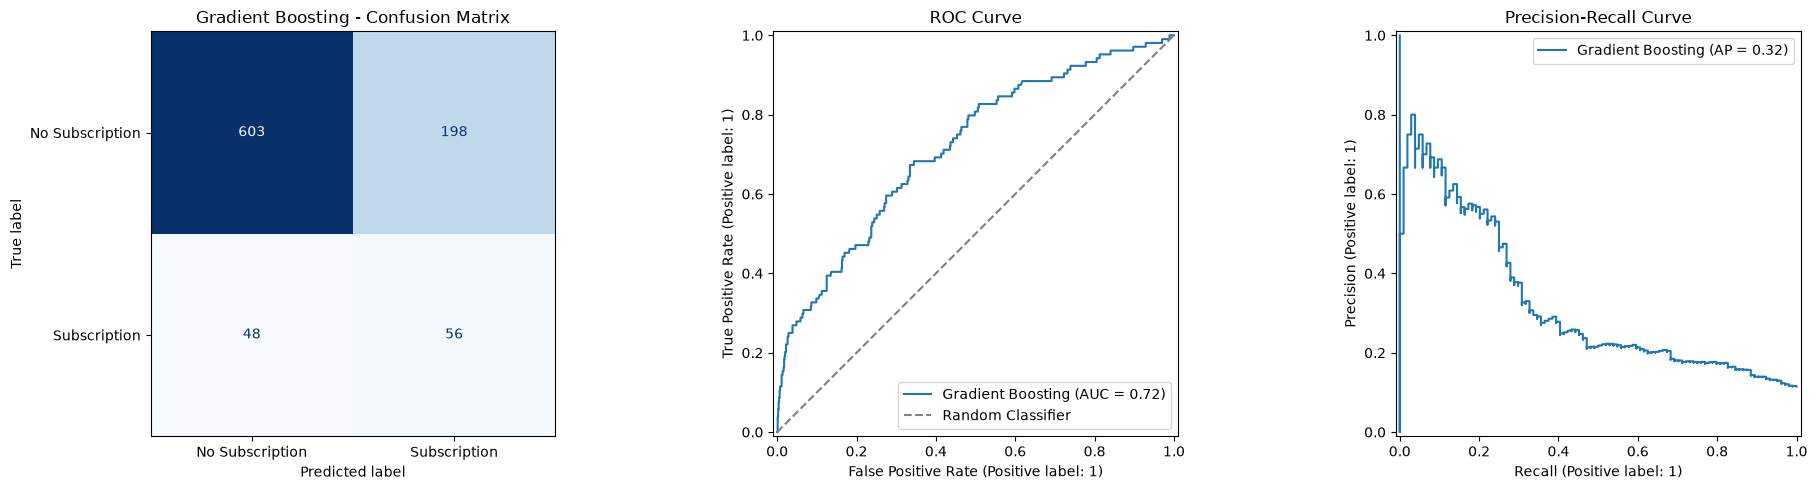

Evaluation visualizations saved: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/evaluation/01_selected_model_evaluation.png


In [11]:
# ============================================================
# 6. CONFUSION MATRIX, ROC AND PRECISION-RECALL CURVES
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    display_labels=["No Subscription", "Subscription"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Gradient Boosting - Confusion Matrix")

# 2. ROC Curve
RocCurveDisplay.from_predictions(
    y_val,
    y_val_proba,
    name="Gradient Boosting",
    ax=axes[1]
)

axes[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

axes[1].set_title("ROC Curve")
axes[1].legend()

# 3. Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(
    y_val,
    y_val_proba,
    name="Gradient Boosting",
    ax=axes[2]
)

axes[2].set_title("Precision-Recall Curve")
axes[2].legend()

plt.tight_layout()

figure_path = IMAGE_DIR / "01_selected_model_evaluation.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Evaluation visualizations saved:", figure_path)

## 7. Classification Threshold Tuning

The default classification threshold of 0.50 is not necessarily optimal for an imbalanced dataset.

Use the validation probabilities to investigate different classification thresholds and identify the threshold that maximizes the F1-score.

Compare the tuned threshold against the default threshold of 0.50 using precision, recall and F1-score.

In [12]:
# ============================================================
# 7. CLASSIFICATION THRESHOLD TUNING
# ============================================================

from sklearn.metrics import precision_recall_curve

precision_values, recall_values, thresholds = precision_recall_curve(
    y_val,
    y_val_proba
)

# Precision and recall contain one extra endpoint
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

# Find threshold with maximum validation F1-score
best_index = np.argmax(f1_values)

best_threshold = thresholds[best_index]

print("=" * 65)
print("CLASSIFICATION THRESHOLD ANALYSIS")
print("=" * 65)

print(f"Default threshold: 0.50")
print(f"Best F1 threshold: {best_threshold:.4f}")
print(f"Maximum validation F1: {f1_values[best_index]:.4f}")

# Evaluate default threshold
default_pred = (y_val_proba >= 0.50).astype(int)

# Evaluate tuned threshold
tuned_pred = (y_val_proba >= best_threshold).astype(int)

threshold_comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-Score"],
    "Default (0.50)": [
        precision_score(y_val, default_pred, zero_division=0),
        recall_score(y_val, default_pred, zero_division=0),
        f1_score(y_val, default_pred, zero_division=0)
    ],
    "Tuned Threshold": [
        precision_score(y_val, tuned_pred, zero_division=0),
        recall_score(y_val, tuned_pred, zero_division=0),
        f1_score(y_val, tuned_pred, zero_division=0)
    ]
})

display(threshold_comparison.round(4))

print("\nThreshold tuning completed successfully.")

CLASSIFICATION THRESHOLD ANALYSIS
Default threshold: 0.50
Best F1 threshold: 0.7419
Maximum validation F1: 0.3436


,Metric,Default (0.50),Tuned Threshold
0,Precision,0.2205,0.4746
1,Recall,0.5385,0.2692
2,F1-Score,0.3128,0.3436



Threshold tuning completed successfully.


## 8. Threshold Performance Visualization

Visualize how precision, recall and F1-score change across different classification thresholds.

This analysis helps understand the trade-off between identifying more potential subscribers and maintaining reliable positive predictions.

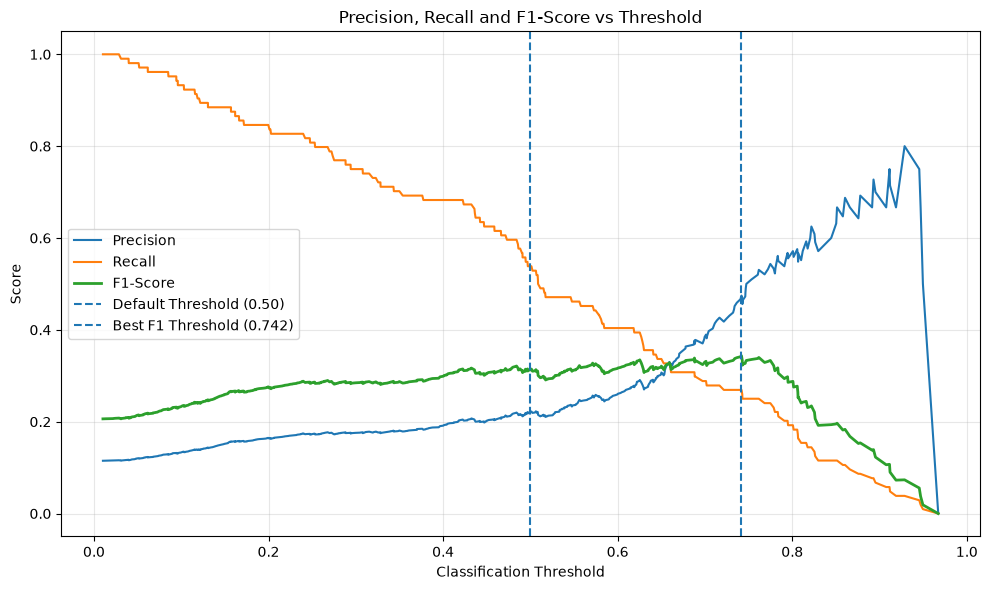

Threshold visualization saved: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/evaluation/02_threshold_performance.png


In [13]:
# ============================================================
# 8. THRESHOLD PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    thresholds,
    precision_values[:-1],
    label="Precision"
)

plt.plot(
    thresholds,
    recall_values[:-1],
    label="Recall"
)

plt.plot(
    thresholds,
    f1_values,
    label="F1-Score",
    linewidth=2
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Default Threshold (0.50)"
)

plt.axvline(
    x=best_threshold,
    linestyle="--",
    label=f"Best F1 Threshold ({best_threshold:.3f})"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1-Score vs Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

figure_path = IMAGE_DIR / "02_threshold_performance.png"

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Threshold visualization saved:", figure_path)

## 9. Cross-Validation Stability Analysis

Stratified 5-fold cross-validation is used to evaluate the consistency of the selected Gradient Boosting model.

The training dataset is divided into five folds. In each iteration, four folds are used for training and one fold is used for validation.

We calculate the mean and standard deviation of Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC across the five folds.

A low standard deviation indicates more consistent model performance across different data partitions.

In [14]:
# ============================================================
# 9. STRATIFIED 5-FOLD CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

print("=" * 65)
print("STRATIFIED 5-FOLD CROSS-VALIDATION")
print("=" * 65)

cv_results = cross_validate(
    selected_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=1
)

cv_summary = []

for metric in scoring:
    validation_scores = cv_results[f"test_{metric}"]
    training_scores = cv_results[f"train_{metric}"]

    cv_summary.append({
        "Metric": metric.upper(),
        "CV Mean": validation_scores.mean(),
        "CV Std": validation_scores.std(),
        "Train Mean": training_scores.mean(),
        "Train-Validation Gap": (
            training_scores.mean() - validation_scores.mean()
        )
    })

cv_summary_df = pd.DataFrame(cv_summary)

display(cv_summary_df.round(4))

print("\nFold-wise validation results:")
for metric in scoring:
    print(
        f"{metric.upper()}:",
        np.round(cv_results[f"test_{metric}"], 4)
    )

print("\nCross-validation completed successfully.")

assert len(cv_results["test_f1"]) == 5
assert cv_summary_df["CV Mean"].notna().all()

STRATIFIED 5-FOLD CROSS-VALIDATION


,Metric,CV Mean,CV Std,Train Mean,Train-Validation Gap
0,ACCURACY,0.7411,0.0157,0.7714,0.0302
1,PRECISION,0.2233,0.0085,0.2772,0.0539
2,RECALL,0.5039,0.0715,0.6097,0.1058
3,F1,0.3085,0.0192,0.3810,0.0725
4,ROC_AUC,0.7103,0.0292,0.7753,0.0650
5,PR_AUC,0.3202,0.0352,0.4117,0.0915



Fold-wise validation results:
ACCURACY: [0.75   0.7289 0.722  0.7663 0.7386]
PRECISION: [0.213  0.2322 0.2269 0.2312 0.2131]
RECALL: [0.4286 0.5904 0.5904 0.4458 0.4643]
F1: [0.2846 0.3333 0.3278 0.3045 0.2921]
ROC_AUC: [0.6734 0.7584 0.7197 0.712  0.6882]
PR_AUC: [0.27   0.3255 0.3367 0.2958 0.3729]

Cross-validation completed successfully.


### Cross-Validation Results — Observations and Business Insights

**Observations:**

- Stratified 5-fold cross-validation was successfully performed using the selected Gradient Boosting pipeline.
- The model achieved a mean accuracy of 0.7411 and mean F1-score of 0.3085.
- The mean ROC-AUC was 0.7103, indicating useful discrimination between subscribers and non-subscribers.
- The F1-score standard deviation was 0.0192, suggesting relatively consistent performance across folds.
- Recall had a higher standard deviation of 0.0715, indicating some variation in identifying actual subscribers.
- Training metrics were higher than validation metrics, showing a generalization gap.

**Business Insights:**

- Cross-validation provides stronger evidence of model reliability than relying on a single validation split.
- The model identifies potential subscribers, but precision needs improvement to reduce unnecessary marketing calls.
- The bank should balance subscriber identification against campaign costs when selecting the final classification threshold.

**Conclusion:**

The selected Gradient Boosting model demonstrates reasonably consistent cross-validation performance. However, its recall and precision trade-off should be considered before real-world deployment.

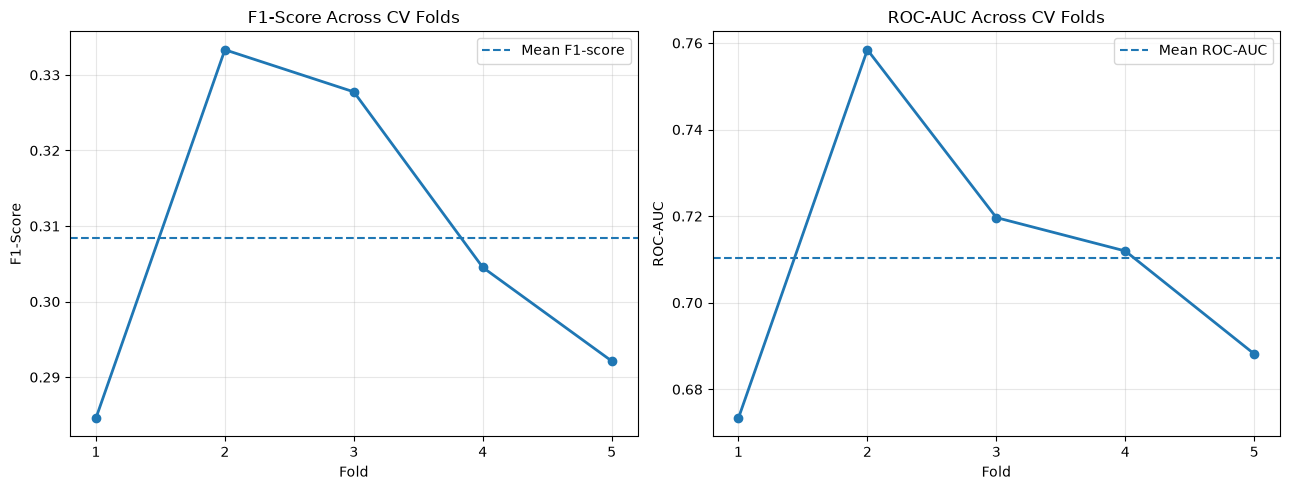

Cross-validation visualization saved: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/evaluation/03_cross_validation_stability.png


In [15]:
# ============================================================
# 10. CROSS-VALIDATION STABILITY VISUALIZATION
# ============================================================

fold_numbers = np.arange(1, N_SPLITS + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# F1-score across folds
axes[0].plot(
    fold_numbers,
    cv_results["test_f1"],
    marker="o",
    linewidth=2
)

axes[0].axhline(
    cv_results["test_f1"].mean(),
    linestyle="--",
    label="Mean F1-score"
)

axes[0].set_title("F1-Score Across CV Folds")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("F1-Score")
axes[0].set_xticks(fold_numbers)
axes[0].legend()
axes[0].grid(alpha=0.3)

# ROC-AUC across folds
axes[1].plot(
    fold_numbers,
    cv_results["test_roc_auc"],
    marker="o",
    linewidth=2
)

axes[1].axhline(
    cv_results["test_roc_auc"].mean(),
    linestyle="--",
    label="Mean ROC-AUC"
)

axes[1].set_title("ROC-AUC Across CV Folds")
axes[1].set_xlabel("Fold")
axes[1].set_ylabel("ROC-AUC")
axes[1].set_xticks(fold_numbers)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

figure_path = IMAGE_DIR / "03_cross_validation_stability.png"

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Cross-validation visualization saved:", figure_path)

In [16]:
# Inspect Phase 6 model comparison report

comparison_df = pd.read_csv(COMPARISON_PATH)

print("MODEL COMPARISON REPORT")
print("=" * 60)

print("Shape:", comparison_df.shape)
print("\nAvailable columns:")
print(comparison_df.columns.tolist())

display(comparison_df.head())

MODEL COMPARISON REPORT
Shape: (5, 45)

Available columns:
['Model', 'Accuracy_Baseline', 'Precision_Baseline', 'Recall_Baseline', 'F1-Score_Baseline', 'ROC-AUC_Baseline', 'PR-AUC_Baseline', 'Accuracy_Tuned', 'Precision_Tuned', 'Recall_Tuned', 'F1-Score_Tuned', 'ROC-AUC_Tuned', 'PR-AUC_Tuned', 'Training Time (s)', 'ACCURACY Mean', 'ACCURACY Std', 'Train ACCURACY Mean', 'PRECISION Mean', 'PRECISION Std', 'Train PRECISION Mean', 'RECALL Mean', 'RECALL Std', 'Train RECALL Mean', 'F1 Mean', 'F1 Std', 'Train F1 Mean', 'ROC_AUC Mean', 'ROC_AUC Std', 'Train ROC_AUC Mean', 'PR_AUC Mean', 'PR_AUC Std', 'Train PR_AUC Mean', 'Best CV PR-AUC', 'Tuning Time (s)', 'Best Parameters', 'True Negatives', 'False Positives', 'False Negatives', 'True Positives', 'Customers Contacted', 'Potential Subscribers Identified', 'Subscribers Missed', 'Precision', 'Recall', 'Final Selection']


,Model,Accuracy_Baseline,Precision_Baseline,Recall_Baseline,F1-Score_Baseline,ROC-AUC_Baseline,PR-AUC_Baseline,Accuracy_Tuned,Precision_Tuned,Recall_Tuned,...,True Negatives,False Positives,False Negatives,True Positives,Customers Contacted,Potential Subscribers Identified,Subscribers Missed,Precision,Recall,Final Selection
0,Logistic Regression,0.670718,0.189103,0.567308,0.283654,0.688046,0.289854,0.670718,0.189103,0.567308,...,548,253,45,59,312,59,45,0.189103,0.567308,Not Selected
1,Decision Tree,0.771271,0.227513,0.413462,0.293515,0.615595,0.161471,0.651934,0.175385,0.548077,...,533,268,47,57,325,57,47,0.175385,0.548077,Not Selected
2,Random Forest,0.816575,0.268657,0.346154,0.302521,0.697908,0.267279,0.696133,0.208191,0.586538,...,569,232,43,61,293,61,43,0.208191,0.586538,Not Selected
3,SVM,0.750276,0.220183,0.461538,0.298137,0.687926,0.237767,0.588950,0.176329,0.701923,...,460,341,31,73,414,73,31,0.176329,0.701923,Not Selected
4,Gradient Boosting,0.740331,0.228216,0.528846,0.318841,0.722126,0.310178,0.728177,0.220472,0.538462,...,603,198,48,56,254,56,48,0.220472,0.538462,Selected


In [17]:
print("ALL 45 MODEL COMPARISON COLUMNS")
print("=" * 65)

for index, column in enumerate(comparison_df.columns, start=1):
    print(f"{index:02d}. {column}")

ALL 45 MODEL COMPARISON COLUMNS
01. Model
02. Accuracy_Baseline
03. Precision_Baseline
04. Recall_Baseline
05. F1-Score_Baseline
06. ROC-AUC_Baseline
07. PR-AUC_Baseline
08. Accuracy_Tuned
09. Precision_Tuned
10. Recall_Tuned
11. F1-Score_Tuned
12. ROC-AUC_Tuned
13. PR-AUC_Tuned
14. Training Time (s)
15. ACCURACY Mean
16. ACCURACY Std
17. Train ACCURACY Mean
18. PRECISION Mean
19. PRECISION Std
20. Train PRECISION Mean
21. RECALL Mean
22. RECALL Std
23. Train RECALL Mean
24. F1 Mean
25. F1 Std
26. Train F1 Mean
27. ROC_AUC Mean
28. ROC_AUC Std
29. Train ROC_AUC Mean
30. PR_AUC Mean
31. PR_AUC Std
32. Train PR_AUC Mean
33. Best CV PR-AUC
34. Tuning Time (s)
35. Best Parameters
36. True Negatives
37. False Positives
38. False Negatives
39. True Positives
40. Customers Contacted
41. Potential Subscribers Identified
42. Subscribers Missed
43. Precision
44. Recall
45. Final Selection


## 11. Comparative Evaluation of All Five Algorithms

The performance of all five machine learning algorithms is compared using F1-score, PR-AUC and ROC-AUC.

Both baseline and tuned validation results are considered. This comparison helps identify improvements achieved through hyperparameter tuning and evaluate the models' ability to identify potential bank subscribers.

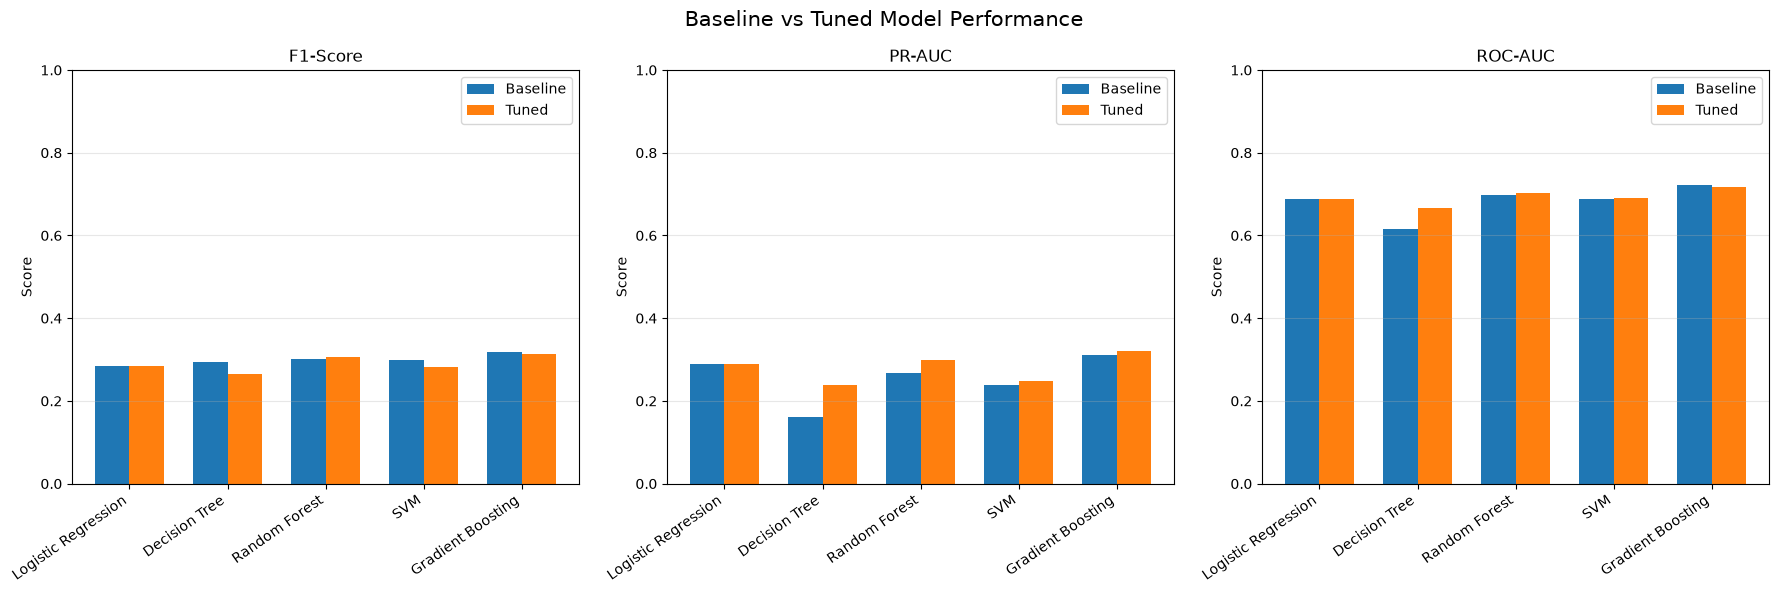

Model comparison visualization saved: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/evaluation/04_five_model_comparison.png


In [18]:
# ============================================================
# 11. FIVE-MODEL PERFORMANCE COMPARISON
# ============================================================

required_columns = [
    "Model",
    "F1-Score_Baseline",
    "F1-Score_Tuned",
    "PR-AUC_Baseline",
    "PR-AUC_Tuned",
    "ROC-AUC_Baseline",
    "ROC-AUC_Tuned"
]

missing_columns = [
    col for col in required_columns
    if col not in comparison_df.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

metrics_to_plot = [
    ("F1-Score_Baseline", "F1-Score_Tuned", "F1-Score"),
    ("PR-AUC_Baseline", "PR-AUC_Tuned", "PR-AUC"),
    ("ROC-AUC_Baseline", "ROC-AUC_Tuned", "ROC-AUC")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

x = np.arange(len(comparison_df))
width = 0.35

for ax, (baseline_col, tuned_col, title) in zip(
    axes, metrics_to_plot
):
    ax.bar(
        x - width / 2,
        comparison_df[baseline_col],
        width,
        label="Baseline"
    )

    ax.bar(
        x + width / 2,
        comparison_df[tuned_col],
        width,
        label="Tuned"
    )

    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.set_xticks(x)
    ax.set_xticklabels(
        comparison_df["Model"],
        rotation=35,
        ha="right"
    )
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Baseline vs Tuned Model Performance",
    fontsize=15
)

plt.tight_layout()

figure_path = IMAGE_DIR / "04_five_model_comparison.png"

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Model comparison visualization saved:", figure_path)

In [19]:
# ============================================================
# 12. QUANTITATIVE MODEL IMPROVEMENT ANALYSIS
# ============================================================

improvement_df = comparison_df[
    [
        "Model",
        "F1-Score_Baseline",
        "F1-Score_Tuned",
        "PR-AUC_Baseline",
        "PR-AUC_Tuned",
        "ROC-AUC_Baseline",
        "ROC-AUC_Tuned"
    ]
].copy()

improvement_df["F1_Change"] = (
    improvement_df["F1-Score_Tuned"]
    - improvement_df["F1-Score_Baseline"]
)

improvement_df["PR_AUC_Change"] = (
    improvement_df["PR-AUC_Tuned"]
    - improvement_df["PR-AUC_Baseline"]
)

improvement_df["ROC_AUC_Change"] = (
    improvement_df["ROC-AUC_Tuned"]
    - improvement_df["ROC-AUC_Baseline"]
)

print("=" * 75)
print("BASELINE VS TUNED MODEL IMPROVEMENTS")
print("=" * 75)

display(improvement_df.round(4))

print("\nBEST MODEL BY TUNED VALIDATION METRICS")

for metric in [
    "F1-Score_Tuned",
    "PR-AUC_Tuned",
    "ROC-AUC_Tuned"
]:
    best_row = comparison_df.loc[
        comparison_df[metric].idxmax()
    ]

    print(
        f"{metric}: {best_row['Model']} "
        f"({best_row[metric]:.4f})"
    )

print("\nQuantitative comparison completed successfully.")

BASELINE VS TUNED MODEL IMPROVEMENTS


,Model,F1-Score_Baseline,F1-Score_Tuned,PR-AUC_Baseline,PR-AUC_Tuned,ROC-AUC_Baseline,ROC-AUC_Tuned,F1_Change,PR_AUC_Change,ROC_AUC_Change
0,Logistic Regression,0.2837,0.2837,0.2899,0.2901,0.6880,0.6882,0.0000,0.0002,0.0001
1,Decision Tree,0.2935,0.2657,0.1615,0.2380,0.6156,0.6673,-0.0278,0.0765,0.0517
2,Random Forest,0.3025,0.3073,0.2673,0.2997,0.6979,0.7022,0.0048,0.0324,0.0043
3,SVM,0.2981,0.2819,0.2378,0.2492,0.6879,0.6905,-0.0163,0.0114,0.0026
4,Gradient Boosting,0.3188,0.3128,0.3102,0.3211,0.7221,0.7171,-0.0060,0.0110,-0.0050



BEST MODEL BY TUNED VALIDATION METRICS
F1-Score_Tuned: Gradient Boosting (0.3128)
PR-AUC_Tuned: Gradient Boosting (0.3211)
ROC-AUC_Tuned: Gradient Boosting (0.7171)

Quantitative comparison completed successfully.


### Model Evaluation — Observations and Business Insights

**1. Overall model performance**

Gradient Boosting achieved the strongest overall tuned validation performance among the five evaluated algorithms, with an F1-score of 0.3128, PR-AUC of 0.3211 and ROC-AUC of 0.7171.

**2. Effect of hyperparameter tuning**

Hyperparameter tuning produced different results across algorithms. Decision Tree showed substantial improvements in PR-AUC and ROC-AUC, while Random Forest achieved modest improvements across all three metrics. This demonstrates that tuning can improve some evaluation metrics while reducing others.

**3. Overfitting and generalization**

The training and validation scores for Gradient Boosting show relatively small performance gaps. Its five-fold cross-validation F1-score was 0.3085 ± 0.0192, suggesting reasonable stability across different training-validation folds.

**4. Classification threshold**

The default classification threshold of 0.50 is not necessarily optimal for an imbalanced dataset. Threshold analysis identified approximately 0.7419 as the threshold producing the highest validation F1-score of 0.3436. This threshold increases precision but reduces recall, demonstrating the trade-off between identifying subscribers and avoiding false positives.

**5. Business impact**

For a bank marketing campaign, identifying potential subscribers is important, but contacting customers who are unlikely to subscribe also creates operational costs. The selected model and classification threshold should therefore reflect the business balance between precision, recall and campaign cost.

**6. Evaluation limitations**

The validation set was used for model comparison and threshold selection. Therefore, these results should not be interpreted as an independent estimate of final performance on completely unseen data. Further independent testing is required.

In [20]:
import json
from pathlib import Path

notebook_path = Path("06_model_evaluation.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

errors_found = []

for i, cell in enumerate(notebook["cells"]):
    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            errors_found.append({
                "cell": i + 1,
                "execution_count": cell.get("execution_count"),
                "error": output.get("ename"),
                "message": output.get("evalue")
            })

print("SAVED NOTEBOOK ERROR DIAGNOSTIC")
print("=" * 55)

if errors_found:
    for error in errors_found:
        print(error)
else:
    print("No saved execution errors found.")

print("\nTotal saved errors:", len(errors_found))

SAVED NOTEBOOK ERROR DIAGNOSTIC
No saved execution errors found.

Total saved errors: 0


In [23]:

import json
from pathlib import Path
import pandas as pd

# ============================================================
# PHASE 7 — FINAL AUDIT
# ============================================================

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

NOTEBOOK_PATH = PROJECT_ROOT / "notebooks" / "06_model_evaluation.ipynb"
REPORT_PATH = PROJECT_ROOT / "reports" / "evaluation_report.md"
IMAGE_DIR = PROJECT_ROOT / "images" / "evaluation"
COMPARISON_PATH = PROJECT_ROOT / "reports" / "model_comparison.csv"

checks = {}

# 1. Notebook exists and is valid JSON
checks["Notebook exists"] = NOTEBOOK_PATH.exists()

try:
    with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
        nb = json.load(f)
    checks["Notebook JSON valid"] = True
except Exception:
    nb = {"cells": []}
    checks["Notebook JSON valid"] = False

# 2. Evaluation report exists and contains content
checks["Evaluation report exists and is non-empty"] = (
    REPORT_PATH.exists() and REPORT_PATH.stat().st_size > 0
)

# 3. Model comparison report exists and is valid
try:
    comparison_df = pd.read_csv(COMPARISON_PATH)
    checks["Model comparison CSV valid"] = (
        comparison_df.shape[0] == 5
        and "Model" in comparison_df.columns
    )
except Exception:
    comparison_df = pd.DataFrame()
    checks["Model comparison CSV valid"] = False

# 4. All five required algorithms are included
required_models = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "SVM",
    "Gradient Boosting"
]

if not comparison_df.empty:
    model_names = comparison_df["Model"].astype(str).tolist()
    checks["All five algorithms included"] = all(
        model in model_names for model in required_models
    )
else:
    checks["All five algorithms included"] = False

# 5. Required evaluation metrics are present
required_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

notebook_text = "\n".join(
    "".join(cell.get("source", []))
    for cell in nb["cells"]
)

checks["All six evaluation metrics included"] = all(
    metric.lower() in notebook_text.lower()
    for metric in required_metrics
)

# 6. Evaluation figures exist
required_figures = [
    "01_selected_model_evaluation.png",
    "02_threshold_performance.png",
    "03_cross_validation_stability.png",
    "04_five_model_comparison.png"
]

checks["All required evaluation figures exist"] = all(
    (IMAGE_DIR / figure).exists()
    for figure in required_figures
)

# 7. Threshold tuning is documented
checks["Threshold tuning included"] = (
    "threshold" in notebook_text.lower()
)

# 8. Cross-validation is included
checks["Cross-validation included"] = (
    "cross-validation" in notebook_text.lower()
    or "cross_validation" in notebook_text.lower()
)

# 9. Business impact and generalization are documented
checks["Business impact and generalization documented"] = (
    "business impact" in notebook_text.lower()
    and "generalization" in notebook_text.lower()
)

# 10. No saved execution errors
saved_errors = []

for i, cell in enumerate(nb["cells"]):
    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            saved_errors.append({
                "cell": i + 1,
                "error": output.get("ename"),
                "message": output.get("evalue")
            })

checks["No notebook execution errors"] = len(saved_errors) == 0

# ============================================================
# AUDIT RESULTS
# ============================================================

print("=" * 65)
print("PHASE 7 — FINAL AUDIT")
print("=" * 65)

for name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")

if saved_errors:
    print("\nSaved notebook errors:")
    for error in saved_errors:
        print(error)

passed_count = sum(checks.values())
total_count = len(checks)

print("\n" + "=" * 65)
print(f"AUDIT RESULT: {passed_count}/{total_count} checks passed")

if all(checks.values()):
    print("PHASE 7 AUDIT PASSED")
else:
    print("PHASE 7 AUDIT NEEDS ATTENTION")

print("=" * 65)


PHASE 7 — FINAL AUDIT
[PASS] Notebook exists
[PASS] Notebook JSON valid
[PASS] Evaluation report exists and is non-empty
[PASS] Model comparison CSV valid
[PASS] All five algorithms included
[PASS] All six evaluation metrics included
[PASS] All required evaluation figures exist
[PASS] Threshold tuning included
[PASS] Cross-validation included
[PASS] Business impact and generalization documented
[PASS] No notebook execution errors

AUDIT RESULT: 11/11 checks passed
PHASE 7 AUDIT PASSED
